In [1]:
%pip install langchain langgraph

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -qU langchain-groq

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sap-ai-sdk-gen 6.1.2 requires pydantic~=2.12, but you have pydantic 2.10.6 which is incompatible.
torchaudio 2.4.1 requires torch==2.4.1, but you have torch 2.4.0 which is incompatible.
ultralytics 8.2.83 requires numpy<2.0.0,>=1.23.0, but you have numpy 2.4.2 which is incompatible.
tensorflow 2.17.0 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.4.2 which is incompatible.
tensorflow 2.17.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 5.29.5 which is incompatible.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install langchain-tavily

Defaulting to user installation because normal site-packages is not writeable
  Using cached langchain_tavily-0.2.18-py3-none-any.whl.metadata (20 kB)
  Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
Using cached langchain_tavily-0.2.18-py3-none-any.whl (30 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.1/548.1 kB 2.4 MB/s eta 0:00:00
Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl (15 kB)
Using cached aiosignal-1.4.0-py3-none-any.whl (7.5 kB)
  Attempting uninstall: aiosignal
    Found existing installation: aiosignal 1.3.1
    Uninstalling aiosignal-1.3.1:
      Successfully uninstalled aiosignal-1.3.1
  Attempting uninstall: aiohappyeyeballs
    Found existing installation: aiohappyeyeballs 2.4.0
    Uninstalling aiohappyeyeballs-2.4.0:
      Successfully uninstalled aiohappyeyeballs-2.4.0
  Attempting uninstall: yarl
    Found existing installation: yarl 1.10.0
    Uninstalling yarl-

In [4]:
%pip install -U "langchain-openrouter"

Defaulting to user installation because normal site-packages is not writeable
  Using cached langchain_openrouter-0.2.9-py3-none-any.whl.metadata (3.4 kB)
  Using cached openrouter-0.11.46-py3-none-any.whl.metadata (9.4 kB)
  Using cached jsonpath_python-1.1.6-py3-none-any.whl.metadata (17 kB)
  Using cached pydantic-2.12.5-py3-none-any.whl.metadata (90 kB)
  Using cached pydantic_core-2.41.5-cp312-cp312-macosx_11_0_arm64.whl.metadata (7.3 kB)
Using cached langchain_openrouter-0.2.9-py3-none-any.whl (30 kB)
Using cached openrouter-0.11.46-py3-none-any.whl (837 kB)
Using cached pydantic-2.12.5-py3-none-any.whl (463 kB)
Using cached pydantic_core-2.41.5-cp312-cp312-macosx_11_0_arm64.whl (1.9 MB)
Using cached jsonpath_python-1.1.6-py3-none-any.whl (14 kB)
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.27.2
    Uninstalling pydantic_core-2.27.2:
      Successfully uninstalled pydantic_core-2.27.2
  Attempting uninstall: pydantic
    Found existing in

In [5]:
%pip install langchain-openai

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
from typing import List,Annotated,TypedDict,Literal
from pydantic import BaseModel,Field
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langchain_openai import ChatOpenAI

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from IPython.display import Image, display
import os

/Users/I528974/Library/Python/3.12/lib/python/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [7]:
os.environ['GROQ_API_KEY'] = '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'
os.environ['TAVILY_API_KEY'] = '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'
os.environ["OPENROUTER_API_KEY"] = "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"

# **Planner Agent**

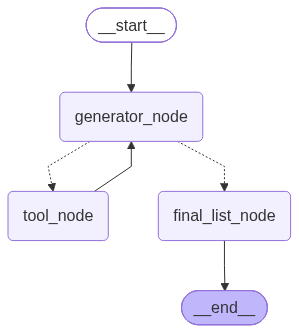

TASK
Confirm Python and API prerequisites
Write a Python script that calls an LLM API (OpenAI, Anthropic, or a local model via Ollama). Demonstrate understanding of tokens, temperature, and context windows. Ensure environment management is set up with uv or poetry.
TASK
Study when to use RAG vs fine-tuning vs long-context
Learn the three approaches for getting knowledge into an LLM. Master the decision rule: RAG for changing/private/external data at scale, fine-tuning for behavior/style changes, long-context for small bounded corpora. Understand the cost math where RAG is ~25x cheaper per query than stuffing a 100k-token window. Be able to explain the RAG-vs-fine-tuning trade-offs (cost and freshness) to a non-technical stakeholder.
TASK
Learn the RAG anatomy and grounding concept
Understand the Indexing -> Retrieval -> Generation pipeline and the concept of grounding (answering only from retrieved context to reduce hallucinations).
TASK
Master embeddings fundamentals
Understand what e

In [12]:
class Task(BaseModel):
  title:str = Field(description='Title of the task')
  description:str = Field(description='Description of the task')

class State(TypedDict):
  messages:Annotated[list,add_messages]
  tasks:List[Task]

class TaskList(BaseModel):
  tasks:List[Task]

search = TavilySearch(max_results=2)

tools = [search]

llm = ChatOpenRouter(model = 'auto')
llm_with_tools = llm.bind_tools(tools)
llm_for_final_list_of_tasks = llm.with_structured_output(TaskList)

def generator_node(state:State):
  response = llm_with_tools.invoke(state['messages'])
  return {'messages':response}

tool_node = ToolNode(tools)

def should_go_to_final_list_of_tasks(state:State):
  last_mssg = state['messages'][-1]

  if last_mssg.tool_calls:
    return 'tool_node'
  return 'final_list_node'

def final_list_node(state:State):
  response = llm_for_final_list_of_tasks.invoke(state['messages'] + [HumanMessage(content='Based on the context generate a list of tasks')])
  return {'tasks':response.tasks}

planner_graph = StateGraph(State)

planner_graph.add_node('generator_node',generator_node)
planner_graph.add_node('tool_node',tool_node)
planner_graph.add_node('final_list_node',final_list_node)

planner_graph.add_edge(START,'generator_node')
planner_graph.add_conditional_edges(
    'generator_node',
    should_go_to_final_list_of_tasks,
    {
      'tool_node':'tool_node',
      'final_list_node':'final_list_node'
    }
    )
planner_graph.add_edge('tool_node','generator_node')
planner_graph.add_edge('final_list_node',END)

planner_agent = planner_graph.compile()

png_bytes = planner_agent.get_graph().draw_mermaid_png()

display(Image(png_bytes))

response = planner_agent.invoke(
    {
        "messages":[
            SystemMessage(content='You are a planner agent. You task is to research and then sketch out a plan of tasks which are actionable.'),
            HumanMessage(content='I want to learn about RAG applications. Teach me RAG so that I am fully professionally ready')
        ]
    }
)

for task in response["tasks"]:
  print("TASK")
  print(task.title)
  print(task.description)

# **Generator Graph - The Subgraph which works on each task**

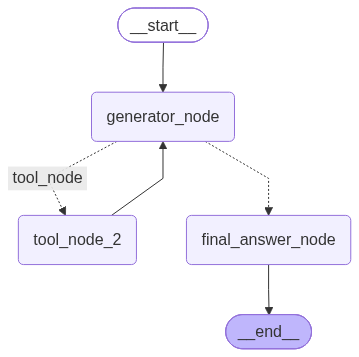

# Confirm Python and API prerequisites — `llm-demo`

A small, runnable project that **verifies the toolchain first**, then calls OpenAI / Anthropic / Ollama behind one interface, making **tokens, temperature and context windows observable** rather than hand-waved.

Three research findings shaped the design:

- **Reasoning-era OpenAI models reject `temperature`** and use `max_completion_tokens` instead of `max_tokens` ([Microsoft Learn](https://learn.microsoft.com/en-us/azure/foundry/openai/how-to/chatgpt), [OpenAI forum](https://community.openai.com/t/temperature-in-gpt-5-models/1337133)) — so a script that hard-codes `temperature=` breaks on `gpt-5`/`o4-mini`.
- **Ollama's OpenAI-compatible `/v1` endpoint silently ignores `num_ctx`** and truncates at the server default (~2048–4096) unless `OLLAMA_CONTEXT_LENGTH` is set on the server or `num_ctx` is baked into a Modelfile ([GitHub issue](https://github.com/openclaw/openclaw/issues/4028), [write-up](https://www.betterclaw.io/blog/ollama

In [13]:
class FinalAnswer(BaseModel):
  answer:str = Field(description='Final answer')

class State2(TypedDict):
  messages:Annotated[list,add_messages]
  final_answer:FinalAnswer

search2 = TavilySearch(max_results=2)

tools2 = [search2]

llm2 = ChatOpenRouter(model = 'auto')
llm_with_tools2 = llm.bind_tools(tools2)
llm_for_final_answer = llm.with_structured_output(FinalAnswer)

def generator_node_2(state:State2):
  response = llm_with_tools2.invoke(state['messages'])
  return {'messages':response}

tool_node_2 = ToolNode(tools2)

def should_go_to_final_answer(state:State2):
  last_mssg = state['messages'][-1]

  if last_mssg.tool_calls:
    return 'tool_node'
  return 'final_answer_node'

def final_answer_node(state:State2):
  response = llm_for_final_answer.invoke(state['messages'] + [HumanMessage(content='Based on the context generate a final answer')])
  return {'final_answer':response}

generator_graph = StateGraph(State2)

generator_graph.add_node('generator_node',generator_node_2)
generator_graph.add_node('tool_node_2',tool_node_2)
generator_graph.add_node('final_answer_node',final_answer_node)

generator_graph.add_edge(START,'generator_node')
generator_graph.add_conditional_edges(
    'generator_node',
    should_go_to_final_answer,
    {
      'tool_node':'tool_node_2',
      'final_answer_node':'final_answer_node'
    }
)
generator_graph.add_edge('tool_node_2','generator_node')
generator_graph.add_edge('final_answer_node',END)

generator_agent = generator_graph.compile()

png_bytes = generator_agent.get_graph().draw_mermaid_png()

display(Image(png_bytes))

task = Task(
    title='Confirm Python and API prerequisites',
    description='Write a Python script that calls an LLM API (OpenAI, Anthropic, or a local model via Ollama). Demonstrate understanding of tokens, temperature, and context windows. Ensure environment management is set up with uv or poetry.'
)

response = generator_agent.invoke(
    {
        "messages":[
            SystemMessage(content='You are a generator agent. You task is to research and then generate a response for the task.'),
            HumanMessage(content=f'Here is your task. Task title: {task.title}. Task description: {task.description}')
        ],
        "final_answer":None
    }
)

print(response['final_answer'].answer)


## **Final Code - Coordinator + Planner + Generator**

In [ ]:

from typing import Annotated, List, TypedDict

from pydantic import BaseModel, Field

from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch
from langchain_openai import ChatOpenAI
from langchain_core.messages import (
    HumanMessage,
    SystemMessage,
    AIMessage,
)
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


# ============================================================
# 1. STRUCTURED OUTPUT MODELS
# ============================================================

class Task(BaseModel):
    title: str = Field(description="Title of the task")
    description: str = Field(description="Description of the task")


class TaskList(BaseModel):
    tasks: List[Task]


class FinalAnswer(BaseModel):
    answer: str = Field(description="Final answer")


class GeneratedTaskResult(BaseModel):
    title: str
    description: str
    answer: str


# ============================================================
# 2. PLANNER AGENT
# ============================================================

class PlannerState(TypedDict):
    messages: Annotated[list, add_messages]
    tasks: List[Task]


planner_search = TavilySearch(max_results=2)
planner_tools = [planner_search]

planner_llm = ChatOpenAI(model="anthropic--claude-4.8-opus",base_url="http://localhost:6655/litellm/v1",api_key="<HAI-API-KEY>")
planner_llm_with_tools = planner_llm.bind_tools(planner_tools)
planner_llm_for_tasks = planner_llm.with_structured_output(TaskList, method="function_calling")


def planner_generator_node(state: PlannerState):
    response = planner_llm_with_tools.invoke(state["messages"])
    return {"messages": response}


planner_tool_node = ToolNode(planner_tools)


def planner_router(state: PlannerState):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return "final_tasks"


def planner_final_tasks_node(state: PlannerState):
    response = planner_llm_for_tasks.invoke(
        state["messages"]
        + [
            HumanMessage(
                content="Based on the context, generate a list of actionable tasks."
            )
        ]
    )

    return {"tasks": response.tasks}


planner_graph = StateGraph(PlannerState)

planner_graph.add_node("generator", planner_generator_node)
planner_graph.add_node("tools", planner_tool_node)
planner_graph.add_node("final_tasks", planner_final_tasks_node)

planner_graph.add_edge(START, "generator")

planner_graph.add_conditional_edges(
    "generator",
    planner_router,
    {
        "tools": "tools",
        "final_tasks": "final_tasks",
    },
)

planner_graph.add_edge("tools", "generator")
planner_graph.add_edge("final_tasks", END)

planner_agent = planner_graph.compile()


# ============================================================
# 3. GENERATOR AGENT
# ============================================================

class GeneratorState(TypedDict):
    messages: Annotated[list, add_messages]
    final_answer: FinalAnswer


generator_search = TavilySearch(max_results=2)
generator_tools = [generator_search]

generator_llm = ChatOpenAI(model="anthropic--claude-4.8-opus",base_url="http://localhost:6655/litellm/v1",api_key="<HAI-API-KEY>")
generator_llm_with_tools = generator_llm.bind_tools(generator_tools)
generator_llm_for_answer = generator_llm.with_structured_output(
    FinalAnswer, method="function_calling"
)


def generator_llm_node(state: GeneratorState):
    response = generator_llm_with_tools.invoke(state["messages"])
    return {"messages": response}


generator_tool_node = ToolNode(generator_tools)


def generator_router(state: GeneratorState):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return "final_answer"


def generator_final_answer_node(state: GeneratorState):
    response = generator_llm_for_answer.invoke(
        state["messages"]
        + [
            HumanMessage(
                content="Based on the context, generate the final answer "
                "for the given task."
            )
        ]
    )

    return {"final_answer": response}


generator_graph = StateGraph(GeneratorState)

generator_graph.add_node("llm", generator_llm_node)
generator_graph.add_node("tools", generator_tool_node)
generator_graph.add_node("final_answer", generator_final_answer_node)

generator_graph.add_edge(START, "llm")

generator_graph.add_conditional_edges(
    "llm",
    generator_router,
    {
        "tools": "tools",
        "final_answer": "final_answer",
    },
)

generator_graph.add_edge("tools", "llm")
generator_graph.add_edge("final_answer", END)

generator_agent = generator_graph.compile()


# ============================================================
# 4. COORDINATOR AGENT
# ============================================================

class CoordinatorState(TypedDict):
    goal: str
    tasks: List[Task]
    generated_results: List[GeneratedTaskResult]
    current_task_index: int


# ------------------------------------------------------------
# Node 1: Call the planner agent
# ------------------------------------------------------------

def coordinator_planner_node(state: CoordinatorState):
    planner_response = planner_agent.invoke(
        {
            "messages": [
                SystemMessage(
                    content=(
                        "You are a planner agent. Research the user's goal "
                        "and create actionable learning tasks."
                    )
                ),
                HumanMessage(content=state["goal"]),
            ]
        }
    )

    return {
        "tasks": planner_response["tasks"],
        "current_task_index": 0,
        "generated_results": [],
    }


# ------------------------------------------------------------
# Node 2: Call the generator for the current task
# ------------------------------------------------------------

def coordinator_generator_node(state: CoordinatorState):
    index = state["current_task_index"]
    task = state["tasks"][index]

    generator_response = generator_agent.invoke(
        {
            "messages": [
                SystemMessage(
                    content=(
                        "You are a generator agent. Research the task "
                        "and produce a useful, detailed response."
                    )
                ),
                HumanMessage(
                    content=(
                        f"Task title: {task.title}\n"
                        f"Task description: {task.description}"
                    )
                ),
            ]
        }
    )

    generated_answer = generator_response["final_answer"]

    task_result = GeneratedTaskResult(
        title=task.title,
        description=task.description,
        answer=generated_answer.answer,
    )

    return {
        "generated_results": (
            state["generated_results"] + [task_result]
        ),
        "current_task_index": index + 1,
    }


# ------------------------------------------------------------
# Routing: Are there tasks left to generate?
# ------------------------------------------------------------

def coordinator_router(state: CoordinatorState):
    if state["current_task_index"] < len(state["tasks"]):
        return "generate"

    return "done"


# ------------------------------------------------------------
# Build the coordinator graph
# ------------------------------------------------------------

coordinator_graph = StateGraph(CoordinatorState)

coordinator_graph.add_node("planner", coordinator_planner_node)
coordinator_graph.add_node("generate", coordinator_generator_node)

coordinator_graph.add_edge(START, "planner")

coordinator_graph.add_conditional_edges(
    "planner",
    coordinator_router,
    {
        "generate": "generate",
        "done": END,
    },
)

coordinator_graph.add_conditional_edges(
    "generate",
    coordinator_router,
    {
        "generate": "generate",
        "done": END,
    },
)

coordinator_agent = coordinator_graph.compile()


# ============================================================
# 5. RUN THE COORDINATOR
# ============================================================

response = coordinator_agent.invoke(
    {
        "goal": (
            "I want to learn about RAG applications. "
            "Teach me RAG so that I am fully professionally ready."
        ),
        "tasks": [],
        "generated_results": [],
        "current_task_index": 0,
    },
    config={"recursion_limit": 1000},
)


# ============================================================
# 6. DISPLAY ALL GENERATED RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL LEARNING PLAN AND GENERATED CONTENT")
print("=" * 70)

for index, result in enumerate(response["generated_results"], start=1):
    print(f"\nTASK {index}: {result.title}")
    print("-" * 70)
    print("DESCRIPTION:")
    print(result.description)
    print("\nGENERATED CONTENT:")
    print(result.answer)
    print("\n" + "=" * 70)



FINAL LEARNING PLAN AND GENERATED CONTENT

TASK 1: Write a RAG concept explainer and decision framework
----------------------------------------------------------------------
DESCRIPTION:
Phase 1 Foundations. Write a one-page explainer covering the problem RAG solves (knowledge cutoff, hallucination) and the core loop: Query → Retrieve → Augment → Generate. Then create a decision tree documenting when to use RAG vs. Long Context vs. SQL/structured query vs. fine-tuning. Deliverable: one-page explainer + decision tree.

GENERATED CONTENT:
# Part 1 — One-Page Explainer: What Is RAG and Why It Exists

## The Problem RAG Solves

Large Language Models (LLMs) are powerful but structurally limited by **how they store knowledge**: everything they "know" is baked into their weights during training. This creates two chronic failures:

**1. Knowledge Cutoff.** A model only knows what existed in its training data up to a fixed date. It cannot know about last week's product launch, today's stock p